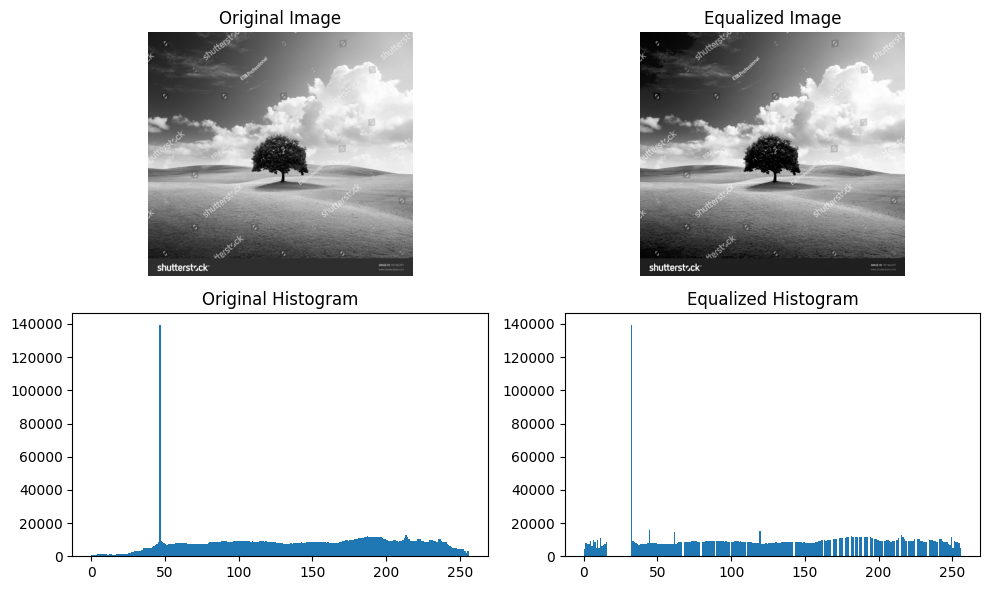

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('sampleimage.jpg', 0)

if img is None:
    raise ValueError("Image not found!")

hist = np.zeros(256, dtype=int)

for pixel in img.ravel():
    hist[pixel] += 1

cdf = np.cumsum(hist)

cdf_min = cdf[np.nonzero(cdf)[0][0]]
total_pixels = img.size

mapping = np.round(
    (cdf - cdf_min) * 255 / (total_pixels - cdf_min)
).clip(0, 255).astype(np.uint8)

equalized_img = mapping[img]

plt.figure(figsize=(10, 6))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(equalized_img, cmap='gray')
plt.title("Equalized Image")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.hist(img.ravel(), bins=256, range=(0, 256))
plt.title("Original Histogram")

plt.subplot(2, 2, 4)
plt.hist(equalized_img.ravel(), bins=256, range=(0, 256))
plt.title("Equalized Histogram")

plt.tight_layout()
plt.show()



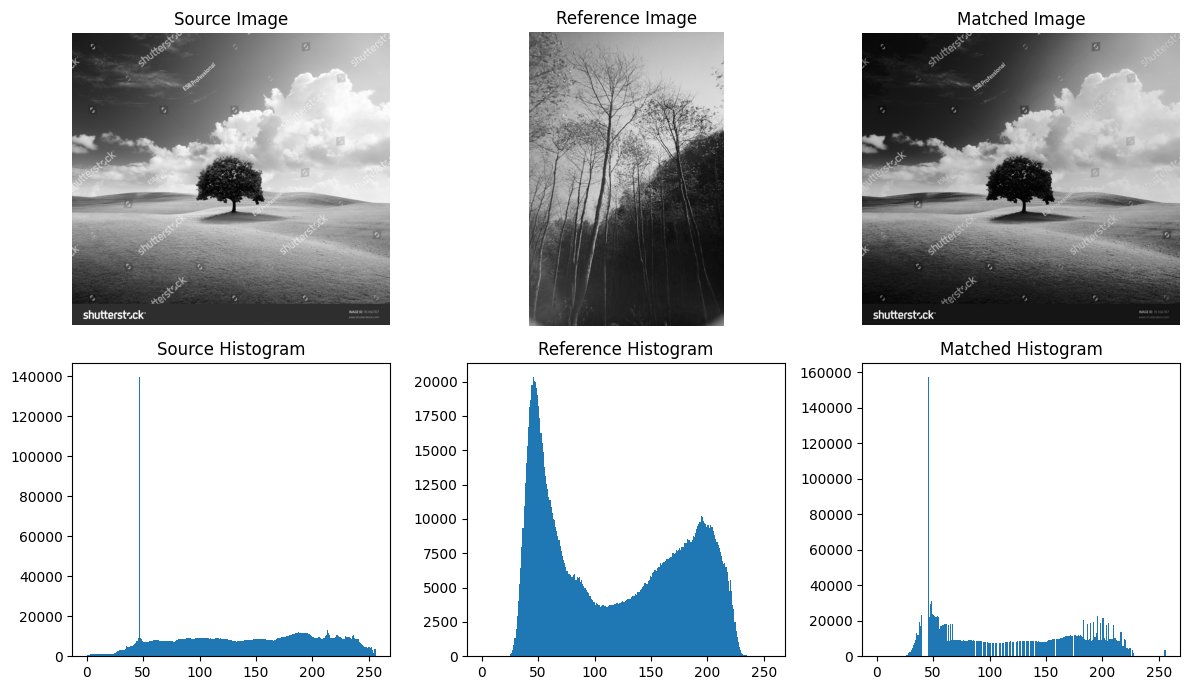

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

source = cv2.imread('sampleimage.jpg', 0)
reference = cv2.imread('photo.avif', 0)

if source is None or reference is None:
    raise ValueError("Image not found!")

source_hist = np.bincount(source.ravel(), minlength=256)
reference_hist = np.bincount(reference.ravel(), minlength=256)

source_cdf = np.cumsum(source_hist) / source.size
reference_cdf = np.cumsum(reference_hist) / reference.size

mapping = np.zeros(256, dtype=np.uint8)

for i in range(256):
    difference = np.abs(reference_cdf - source_cdf[i])
    mapping[i] = np.argmin(difference)

matched_img = mapping[source]

plt.figure(figsize=(12, 7))

plt.subplot(2, 3, 1)
plt.imshow(source, cmap='gray')
plt.title("Source Image")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(reference, cmap='gray')
plt.title("Reference Image")
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(matched_img, cmap='gray')
plt.title("Matched Image")
plt.axis('off')

plt.subplot(2, 3, 4)
plt.hist(source.ravel(), bins=256, range=(0, 256))
plt.title("Source Histogram")

plt.subplot(2, 3, 5)
plt.hist(reference.ravel(), bins=256, range=(0, 256))
plt.title("Reference Histogram")

plt.subplot(2, 3, 6)
plt.hist(matched_img.ravel(), bins=256, range=(0, 256))
plt.title("Matched Histogram")

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')